# 01 · Experiment case study: which headline should we ship?

**Business question.** Upworthy wrote five headlines for the same story and randomly showed one of them to each visitor who saw the story preview. Should the editors replace their original headline with one of the challengers, and how confident can they be?

**Data.** One real experiment from the [Upworthy Research Archive](https://upworthy.natematias.com/) (Matias et al., 2021, *Scientific Data*). The archive has 32,487 real headline A/B tests run between 2013 and 2015. This notebook covers one test end to end. Notebook 02 scales the same methods to 1,825 tests.

**Why this test?** It was picked as a clean teaching example: only the headline varies (same image, excerpt and share text), it has 5 arms with about 7,000 impressions each, it ran outside the archive's documented randomization-problem window, and it passes a sample-ratio check. It was also picked *because* it has a clear result, so treat it as an illustration. It is not a typical test. Notebook 02 shows what typical looks like.

**What this notebook covers**
1. Experiment design and pre-registered decision rule
2. Validity guardrail: sample-ratio mismatch (SRM)
3. CTR with Wilson confidence intervals
4. Omnibus chi-square test
5. Pairwise tests vs control + multiple-comparison correction
6. Power analysis and minimum detectable effect
7. Bayesian analysis: P(best), P(B > A), lift credible interval, expected loss, prior sensitivity
8. Practical significance and the decision

In [1]:
import sys, json
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from abtest import data, frequentist as fq, power, bayesian as bayes, plotting as P

P.apply_style()
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
RESULTS = {}

## 1 · Experiment design

| Element | Choice |
|---|---|
| **Hypothesis** | H₀: every headline has the same click-through rate. H₁: at least one headline's CTR differs from the original. |
| **Unit of randomization** | A preview impression. The archive randomized at the impression level, and user-level data was not released. |
| **Primary metric** | CTR = clicks / impressions |
| **Control** | The *first headline the editor wrote* (earliest `created_at`). Upworthy had no formal control, so the original draft is the status quo a challenger has to beat. |
| **Treatments** | The 4 later headlines |
| **Significance level** | α = 0.05 two-sided, with **Holm** correction across the 4 comparisons with control |
| **Decision rule (set before looking)** | Ship a challenger only if (a) it beats control after Holm correction, and (b) Bayesian P(best) ≥ 95% with expected loss < 0.01 percentage points. Otherwise keep the original. |

> **Assumption to keep in mind:** the tests below treat impressions as independent Bernoulli trials. If one person sees a preview several times, impressions are correlated and the p-values will be slightly overconfident. Notebook 02 measures how big this problem is in the archive.

In [2]:
TEST_ID = "54345144b2454b5a9d000061"

df = data.load_packages("exploratory")
test = (df[df["test_id"] == TEST_ID]
        .sort_values("created_at")
        .reset_index(drop=True))
test["label"] = [chr(ord("A") + i) for i in range(len(test))]
test["is_control"] = test.index == 0

assert test["eyecatcher_id"].nunique() == 1 and test["headline"].nunique() == len(test)
assert not test["problem"].any()

test[["label", "headline", "impressions", "clicks", "created_at"]]

,label,headline,impressions,clicks,created_at
0,A,These Stats Are Heartbreaking Because This Is So Real ... And Happening In Your Neighborhood.,7165,41,2014-10-07 20:47:47.505
1,B,They're Just A Bunch Of Little Doodles In A Kid's Notebook. So Why Is It So Upsetting?,7164,92,2014-10-07 20:48:03.672
2,C,It's On Notebook Paper To Remind You That These Are Just Kids. And They Need Your Help.,7068,38,2014-10-07 20:48:18.556
3,D,"What Does A Sheet Of Notebook Paper, A Hashtag, And A Ridiculous Amount Of Buses Have In Common?",7146,24,2014-10-07 20:49:31.662
4,E,There's Enough Of These Kids To Fill 223 Stadiums — And That's Not Even The Real Kicker Here,7217,23,2014-10-07 20:51:00.546


## 2 · Guardrail: sample-ratio mismatch

Before reading any outcome, check that the randomizer did its job. With an equal split, each arm should get about the same number of impressions. A chi-square goodness-of-fit test with p < 0.001 would point to broken randomization or logging, and every downstream result would be suspect. This check matters for this archive in particular. Notebook 02 shows it independently rediscovers the randomization bug the archive's maintainers reported.

In [3]:
srm_chi2, srm_p = fq.srm_test(test["impressions"])
share = test["impressions"] / test["impressions"].sum()
print(f"Traffic share per arm: {', '.join(f'{l} {s:.1%}' for l, s in zip(test['label'], share))}")
print(f"SRM chi-square = {srm_chi2:.2f}, p = {srm_p:.3f} -> {'PASS' if srm_p >= 0.001 else 'FAIL'}")
RESULTS["srm_p"] = srm_p

Traffic share per arm: A 20.0%, B 20.0%, C 19.8%, D 20.0%, E 20.2%
SRM chi-square = 1.63, p = 0.804 -> PASS


## 3 · Click-through rate per headline

The Wilson score interval is used instead of the textbook Wald interval. At CTRs below 2%, Wald intervals have poor coverage and can even go below zero.

In [4]:
lo, hi = fq.wilson_ci(test["clicks"], test["impressions"])
test["ctr_lo"], test["ctr_hi"] = lo, hi
test[["label", "impressions", "clicks", "ctr", "ctr_lo", "ctr_hi"]]

,label,impressions,clicks,ctr,ctr_lo,ctr_hi
0,A,7165,41,0.0057,0.0042,0.0078
1,B,7164,92,0.0128,0.0105,0.0157
2,C,7068,38,0.0054,0.0039,0.0074
3,D,7146,24,0.0034,0.0023,0.0050
4,E,7217,23,0.0032,0.0021,0.0048


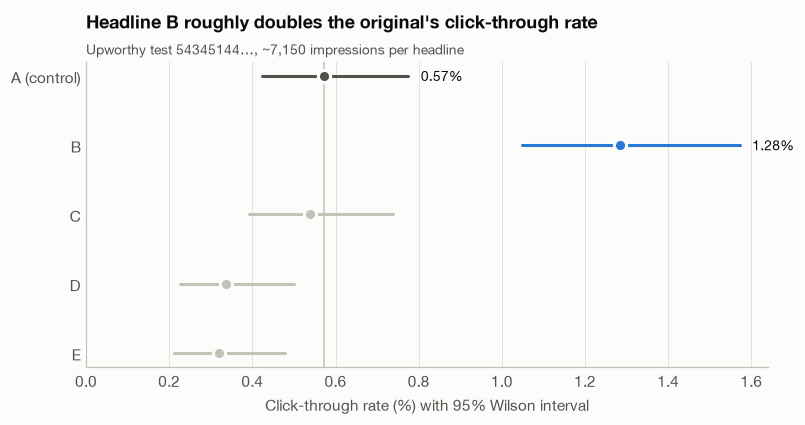

In [5]:
best = int(test["ctr"].idxmax())
order = test.index[::-1]

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, r in test.iterrows():
    y = list(order).index(i)
    color = P.BLUE if i == best else (P.INK_2 if r.is_control else P.CONTEXT)
    ax.plot([r.ctr_lo * 100, r.ctr_hi * 100], [y, y], color=color, lw=2, solid_capstyle="round")
    ax.plot(r.ctr * 100, y, "o", color=color, ms=8, mec=P.SURFACE, mew=2)
    if i == best or r.is_control:
        ax.text(r.ctr_hi * 100 + 0.03, y, f"{r.ctr:.2%}", va="center", color=P.INK, fontsize=9)
ax.axvline(test.loc[0, "ctr"] * 100, color=P.AXIS, lw=1, zorder=0)
ax.set_yticks(range(len(test)))
ax.set_yticklabels([f"{test.loc[i, 'label']}{' (control)' if i == 0 else ''}" for i in order])
ax.set_xlabel("Click-through rate (%) with 95% Wilson interval")
ax.set_xlim(0, None)
ax.grid(axis="y", visible=False)
ax.set_title("Headline B roughly doubles the original's click-through rate")
P.subtitle(ax, f"Upworthy test {TEST_ID[:8]}…, ~7,150 impressions per headline")
P.save(fig, "01_case_ctr_intervals")
plt.show()

## 4 · Omnibus test: is there *any* difference?

A k × 2 chi-square test of independence asks one question: do the five CTRs differ more than chance would explain? Running it first protects against fishing. If it were not significant, we would stop here.

In [6]:
chi2, dof, omni_p = fq.omnibus_chi2(test["clicks"], test["impressions"])
print(f"chi-square({dof}) = {chi2:.1f}, p = {omni_p:.2e}")
RESULTS["omnibus_p"] = omni_p

chi-square(4) = 73.5, p = 4.15e-15


## 5 · Pairwise comparisons with control and multiple-comparison correction

Each challenger is compared with the original using a pooled two-proportion z-test. With 4 comparisons at α = 0.05, the chance of at least one false "winner" when nothing is going on is about 1 − 0.95⁴ ≈ 19%, not 5%. So we adjust:

| Method | Controls | Behaviour |
|---|---|---|
| **Bonferroni** | Family-wise error rate (FWER) | Multiply every p by m. Simple and the most conservative. |
| **Holm** | FWER | Step-down Bonferroni. Uniformly more powerful, with the same guarantee. *This is our pre-registered choice.* |
| **Benjamini–Hochberg** | False discovery rate (FDR) | Allows a small share of false winners in exchange for power. Better suited to screening many ideas than to a single ship decision. |

In [7]:
comp = fq.compare_to_control(test)
show = comp.assign(**{c: comp[c] * 100 for c in ["ctr", "diff", "diff_lo", "diff_hi"]},
                   **{c: comp[c] * 100 for c in ["lift", "lift_lo", "lift_hi"]})
show.rename(columns={"ctr": "ctr_%", "diff": "diff_pp", "diff_lo": "diff_lo_pp", "diff_hi": "diff_hi_pp",
                     "lift": "lift_%", "lift_lo": "lift_lo_%", "lift_hi": "lift_hi_%"}).round(4)

,label,impressions,clicks,ctr_%,diff_pp,diff_lo_pp,diff_hi_pp,lift_%,lift_lo_%,lift_hi_%,z,p_raw,p_bonferroni,p_holm,p_fdr_bh
0,B,7164,92,1.2842,0.7120,0.3982,1.0258,124.4216,55.5476,223.7918,4.4437,0.0000,0.0000,0.0000,0.0000
1,C,7068,38,0.5376,-0.0346,-0.2787,0.2095,-6.0451,-39.4969,45.9019,-0.2777,0.7812,1.0000,0.7812,0.7812
2,D,7146,24,0.3359,-0.2364,-0.4566,-0.0162,-41.3078,-64.4964,-2.9738,-2.1027,0.0355,0.1420,0.0710,0.0473
3,E,7217,23,0.3187,-0.2535,-0.4713,-0.0358,-44.3066,-66.5415,-7.2956,-2.2840,0.0224,0.0895,0.0671,0.0447


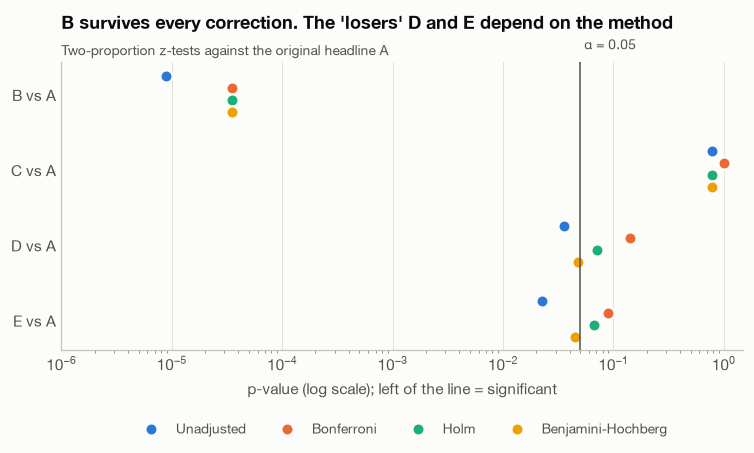

Significant comparisons by method: {'Unadjusted': 3, 'Bonferroni': 1, 'Holm': 1, 'Benjamini-Hochberg': 3}


In [8]:
methods = [("p_raw", "Unadjusted", P.BLUE), ("p_bonferroni", "Bonferroni", P.ORANGE),
           ("p_holm", "Holm", P.AQUA), ("p_fdr_bh", "Benjamini-Hochberg", P.YELLOW)]
fig, ax = plt.subplots(figsize=(8, 3.4))
offsets = np.linspace(-0.24, 0.24, len(methods))
for (col, name, color), off in zip(methods, offsets):
    ax.plot(comp[col], np.arange(len(comp)) + off, "o", color=color, ms=8, mec=P.SURFACE, mew=1.5, label=name)
ax.axvline(0.05, color=P.INK_2, lw=1)
ax.text(0.05, -0.55, " α = 0.05", color=P.INK_2, fontsize=9, va="bottom")
ax.set_xscale("log")
ax.set_xlim(1e-6, 1.5)
ax.set_yticks(range(len(comp)))
ax.set_yticklabels([f"{l} vs A" for l in comp["label"]])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("p-value (log scale); left of the line = significant")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=4)
ax.set_title("B survives every correction. The 'losers' D and E depend on the method")
P.subtitle(ax, "Two-proportion z-tests against the original headline A")
P.save(fig, "02_case_corrections")
plt.show()

summary = {m: int((comp[c] < 0.05).sum()) for c, m, _ in methods}
print("Significant comparisons by method:", summary)
RESULTS["significant_by_method"] = summary

**Reading it.** Headline B is better than the original by a margin that survives every correction. D and E are significantly *worse* than the original before correction (and under BH), but not under Holm or Bonferroni. That shows how the choice of correction can change the story you tell, which is why it has to be fixed before the data comes in.

## 6 · Power analysis

Power answers two design questions:

1. **Before the test:** with about 7,150 impressions per arm and a baseline CTR of 0.57%, what is the smallest lift we could reliably detect (the minimum detectable effect, MDE)?
2. **For the next test:** how much traffic would a realistic 10–20% lift need?

> We deliberately do **not** compute "observed power" from the observed effect. It is a one-to-one transform of the p-value and adds no information.

In [9]:
p0 = test.loc[0, "ctr"]
n_arm = int(test["impressions"].mean())
m = len(comp)

mde_raw = power.mde(p0, n_arm, alpha=0.05)
mde_bonf = power.mde(p0, n_arm, alpha=0.05 / m)
print(f"Baseline CTR {p0:.3%}, {n_arm:,} impressions per arm")
print(f"MDE at 80% power: {mde_raw:+.0%} relative (α = 0.05), {mde_bonf:+.0%} relative (α = 0.05/{m})")

need = pd.DataFrame({"relative_lift": [0.05, 0.10, 0.20, 0.50, 1.00]})
need["n_per_arm_alpha_0.05"] = [power.sample_size_per_arm(p0, l) for l in need.relative_lift]
need["n_per_arm_bonferroni"] = [power.sample_size_per_arm(p0, l, alpha=0.05 / m) for l in need.relative_lift]
need["total_impressions_5_arms"] = need["n_per_arm_bonferroni"] * len(test)
RESULTS.update(mde_raw=mde_raw, mde_bonf=mde_bonf, n_arm=n_arm, baseline_ctr=p0)
need

Baseline CTR 0.572%, 7,152 impressions per arm
MDE at 80% power: +71% relative (α = 0.05), +87% relative (α = 0.05/4)


,relative_lift,n_per_arm_alpha_0.05,n_per_arm_bonferroni,total_impressions_5_arms
0,0.0500,1117980,1588346,7941730
1,0.1000,286152,406544,2032720
2,0.2000,74811,106286,531430
3,0.5000,13482,19154,95770
4,1.0000,3964,5632,28160


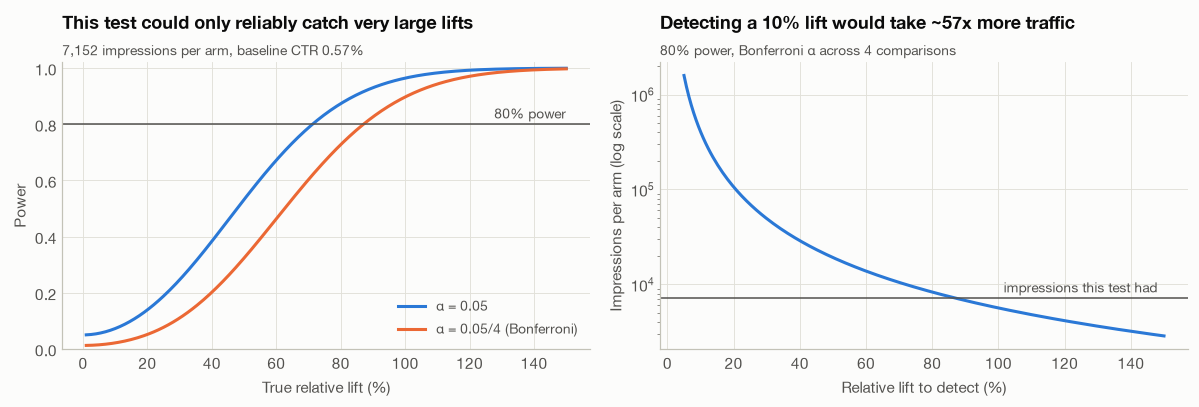

In [10]:
lifts = np.linspace(0.01, 1.5, 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(lifts * 100, [power.power_at(p0, l, n_arm) for l in lifts], color=P.BLUE, label="α = 0.05")
ax.plot(lifts * 100, [power.power_at(p0, l, n_arm, alpha=0.05 / m) for l in lifts], color=P.ORANGE,
        label=f"α = 0.05/{m} (Bonferroni)")
ax.axhline(0.8, color=P.INK_2, lw=1)
ax.text(150, 0.81, "80% power", ha="right", va="bottom", color=P.INK_2, fontsize=9)
ax.set_xlabel("True relative lift (%)")
ax.set_ylabel("Power")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.set_title("This test could only reliably catch very large lifts")
P.subtitle(ax, f"{n_arm:,} impressions per arm, baseline CTR {p0:.2%}")

ax = axes[1]
lifts2 = np.linspace(0.05, 1.5, 200)
ax.plot(lifts2 * 100, [power.sample_size_per_arm(p0, l, alpha=0.05 / m) for l in lifts2], color=P.BLUE)
ax.axhline(n_arm, color=P.INK_2, lw=1)
ax.text(148, n_arm * 1.15, "impressions this test had", ha="right", color=P.INK_2, fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("Relative lift to detect (%)")
ax.set_ylabel("Impressions per arm (log scale)")
ratio = power.sample_size_per_arm(p0, 0.10, alpha=0.05 / m) / n_arm
ax.set_title(f"Detecting a 10% lift would take ~{ratio:.0f}x more traffic")
P.subtitle(ax, "80% power, Bonferroni α across 4 comparisons")
fig.tight_layout()
P.save(fig, "03_case_power")
plt.show()

## 7 · Bayesian analysis

Frequentist output answers "how surprising is this data if nothing is going on?" A product manager usually wants "what is the probability B is really better, and what do I risk by shipping it?" The Beta-Binomial model answers that directly:

- Prior on each arm's CTR: Beta(1, 1) (flat)
- Posterior: Beta(1 + clicks, 1 + impressions − clicks)
- Monte Carlo draws give **P(best)**, **P(B > A)**, the **posterior distribution of relative lift**, and **expected loss**, which is the CTR we would give up on average if we shipped an arm that turned out not to be the best.

In [11]:
draws = bayes.sample_posteriors(test["clicks"], test["impressions"], prior=(1, 1), draws=400_000, seed=42)
test["p_best"] = bayes.prob_best(draws)
test["expected_loss_pp"] = bayes.expected_loss(draws) * 100
test["p_beats_control"] = [bayes.prob_beats(draws, i, 0) for i in range(len(test))]

lift = bayes.relative_lift(draws, best, 0)
lift_lo, lift_hi = bayes.credible_interval(lift)
print(f"P({test.loc[best, 'label']} > A) = {bayes.prob_beats(draws, best, 0):.4f}")
print(f"Relative lift {test.loc[best, 'label']} vs A: median {np.median(lift):+.0%}, 95% credible interval [{lift_lo:+.0%}, {lift_hi:+.0%}]")
RESULTS.update(p_best=float(test.loc[best, "p_best"]), lift_median=float(np.median(lift)),
               lift_cri=[float(lift_lo), float(lift_hi)],
               expected_loss_best_pp=float(test.loc[best, "expected_loss_pp"]))
test[["label", "ctr", "p_best", "p_beats_control", "expected_loss_pp"]]

P(B > A) = 1.0000
Relative lift B vs A: median +123%, 95% credible interval [+56%, +223%]


,label,ctr,p_best,p_beats_control,expected_loss_pp
0,A,0.0057,0.0000,0.0000,0.7122
1,B,0.0128,1.0000,1.0000,0.0000
2,C,0.0054,0.0000,0.3925,0.7463
3,D,0.0034,0.0000,0.0179,0.9482
4,E,0.0032,0.0000,0.0115,0.9657


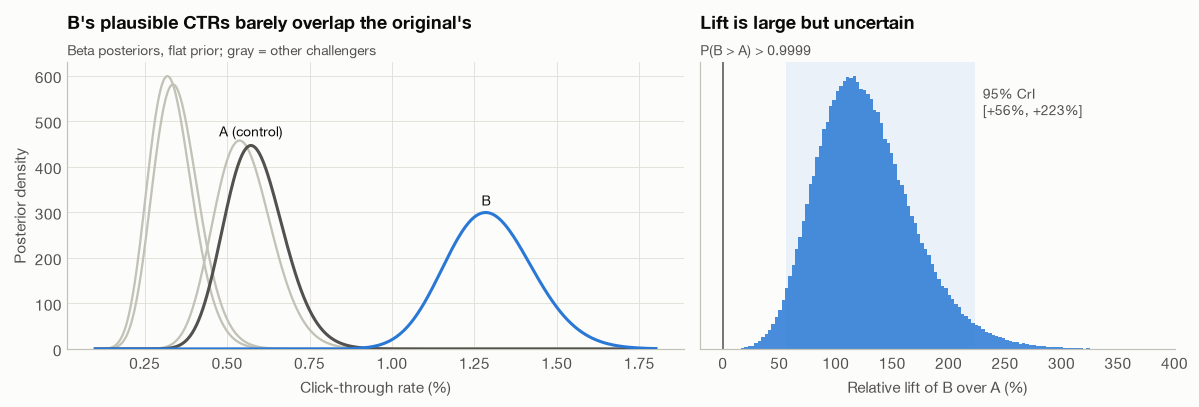

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
x = np.linspace(0.001, 0.018, 800)
a, b = bayes.posterior_params(test["clicks"], test["impressions"])
for i in range(len(test)):
    color = P.BLUE if i == best else (P.INK_2 if i == 0 else P.CONTEXT)
    dens = stats.beta.pdf(x, a[i], b[i])
    ax.plot(x * 100, dens, color=color, lw=2 if i in (0, best) else 1.5, zorder=3 if i in (0, best) else 2)
    if i in (0, best):
        k = dens.argmax()
        ax.text(x[k] * 100, dens[k] * 1.03, "A (control)" if i == 0 else test.loc[i, "label"],
                ha="center", va="bottom", color=P.INK, fontsize=9)
ax.set_xlabel("Click-through rate (%)")
ax.set_ylabel("Posterior density")
ax.set_ylim(0, None)
ax.set_title("B's plausible CTRs barely overlap the original's")
P.subtitle(ax, "Beta posteriors, flat prior; gray = other challengers")

ax = axes[1]
ax.hist(lift * 100, bins=np.linspace(-20, 400, 141), color=P.BLUE, alpha=0.85)
ax.set_xlim(-20, 400)
ax.axvspan(lift_lo * 100, lift_hi * 100, color=P.BLUE, alpha=0.08, lw=0)
ax.axvline(0, color=P.INK_2, lw=1)
ax.text(lift_hi * 100, ax.get_ylim()[1] * 0.92, f"  95% CrI\n  [{lift_lo:+.0%}, {lift_hi:+.0%}]", color=P.INK_2, fontsize=9, va="top")
ax.set_xlabel("Relative lift of B over A (%)")
ax.set_yticks([])
ax.grid(False)
ax.set_title("Lift is large but uncertain")
pba = bayes.prob_beats(draws, best, 0)
P.subtitle(ax, "P(B > A) > 0.9999" if pba > 0.9999 else f"P(B > A) = {pba:.4f}")
fig.tight_layout()
P.save(fig, "04_case_bayes")
plt.show()

### Prior sensitivity

A flat prior lets the data speak, but it ignores everything we know about headline CTRs. As a check, we fit a Beta prior to the control CTRs of all 1,825 clean headline tests (method of moments). We also try a deliberately *skeptical* prior: the same portfolio mean CTR for every arm, worth 20,000 pseudo-impressions per arm (about 3× the data in each arm). It pulls all five headlines toward the same CTR. If the decision survives even that, it is robust.

In [13]:
arms = data.headline_arms(df)
ctl_ctr = arms.loc[arms["is_control"], "ctr"]
prior_full = bayes.fit_beta_prior(ctl_ctr)
m_ctr = prior_full[0] / sum(prior_full)
skeptical = (m_ctr * 20_000, (1 - m_ctr) * 20_000)
print(f"Portfolio prior (moments): Beta({prior_full[0]:.2f}, {prior_full[1]:.1f}), mean CTR {m_ctr:.2%}, worth {sum(prior_full):.0f} impressions")
print(f"Skeptical prior:           Beta({skeptical[0]:.0f}, {skeptical[1]:,.0f})")

rows = []
for name, pr in [("Flat Beta(1,1)", (1, 1)), ("Portfolio (moments)", prior_full), ("Skeptical (20,000 pseudo-impr.)", skeptical)]:
    d = bayes.sample_posteriors(test["clicks"], test["impressions"], prior=pr, draws=200_000, seed=7)
    lf = bayes.relative_lift(d, best, 0)
    rows.append({"prior": name, "P(B best)": bayes.prob_best(d)[best], "P(B > A)": bayes.prob_beats(d, best, 0),
                 "lift median": np.median(lf), "lift 2.5%": np.quantile(lf, 0.025), "lift 97.5%": np.quantile(lf, 0.975)})
sens = pd.DataFrame(rows)
RESULTS["prior_sensitivity"] = sens.to_dict(orient="records")
sens

Portfolio prior (moments): Beta(1.79, 139.1), mean CTR 1.27%, worth 141 impressions
Skeptical prior:           Beta(254, 19,746)


,prior,P(B best),P(B > A),lift median,lift 2.5%,lift 97.5%
0,"Flat Beta(1,1)",1.0000,1.0000,1.2238,0.5555,2.2370
1,Portfolio (moments),1.0000,1.0000,1.2018,0.5430,2.1939
2,"Skeptical (20,000 pseudo-impr.)",0.9613,0.9790,0.1737,0.0060,0.3702


## 8 · Practical significance and the decision

Statistical significance says the effect is probably real. Practical significance asks whether it is worth acting on. For a publisher, the cleanest translation is extra readers per million preview impressions.

In [14]:
d_abs = test.loc[best, "ctr"] - p0
ci = comp.loc[comp["label"] == test.loc[best, "label"], ["diff_lo", "diff_hi"]].iloc[0]
print(f"Absolute gain: {d_abs * 100:+.2f} pp (95% CI {ci.diff_lo * 100:+.2f} to {ci.diff_hi * 100:+.2f} pp)")
print(f"= {d_abs * 1e6:,.0f} extra clicks per 1M impressions (95% CI {ci.diff_lo * 1e6:,.0f} to {ci.diff_hi * 1e6:,.0f})")

holm_ok = comp.loc[comp["label"] == test.loc[best, "label"], "p_holm"].iloc[0] < 0.05
bayes_ok = test.loc[best, "p_best"] >= 0.95 and test.loc[best, "expected_loss_pp"] < 0.01
print(f"\nDecision rule: Holm-significant = {holm_ok}, P(best) >= 95% & loss < 0.01pp = {bayes_ok}")
print("DECISION:", f"ship headline {test.loc[best, 'label']}" if holm_ok and bayes_ok else "keep the original")
RESULTS.update(abs_gain_pp=float(d_abs * 100), clicks_per_million=float(d_abs * 1e6),
               decision_ship=bool(holm_ok and bayes_ok), best_label=test.loc[best, "label"],
               best_headline=test.loc[best, "headline"], control_headline=test.loc[0, "headline"])

Absolute gain: +0.71 pp (95% CI +0.40 to +1.03 pp)
= 7,120 extra clicks per 1M impressions (95% CI 3,982 to 10,258)

Decision rule: Holm-significant = True, P(best) >= 95% & loss < 0.01pp = True
DECISION: ship headline B


In [15]:
with open("../reports/results/01_case_study.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)